## Lab 3 — Millions of TVs, Who Is Watching?
# Name: Artem Novikov / Group: КМ-43

### Setup

In [37]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")

acr_sessions['start_et'] = pd.to_datetime(acr_sessions['start_utc']).dt.tz_convert('US/Eastern')
acr_sessions['end_et'] = pd.to_datetime(acr_sessions['end_utc']).dt.tz_convert('US/Eastern')

acr_sessions['duration_sec'] = (acr_sessions['end_et'] - acr_sessions['start_et']).dt.total_seconds()

acr_sessions['broadcast_date'] = (acr_sessions['start_et'] - pd.Timedelta(hours=6)).dt.date

print("--- Setup & Preprocessing Check ---")
print(f"Total ACR sessions loaded: {len(acr_sessions):,}")
print(f"Unique TVs: {acr_sessions['tv_id'].nunique():,}")
print(f"Broadcast dates range: {acr_sessions['broadcast_date'].min()} to {acr_sessions['broadcast_date'].max()}")
print("\nFirst 3 rows of processed acr_sessions:")
print(acr_sessions[['session_id', 'tv_id', 'start_et', 'duration_sec', 'broadcast_date', 'session_type', 'network_code']].head(3))

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.
--- Setup & Preprocessing Check ---
Total ACR sessions loaded: 6,392,981
Unique TVs: 29,940
Broadcast dates range: 2024-10-14 to 2024-10-27

First 3 rows of processed acr_sessions:
   session_id    tv_id                  start_et  duration_sec broadcast_date  \
0   900000001  7000070 2024-10-14 06:00:00-04:00         765.0     2024-10-14   
1   900000002  7001293 2024-10-14 06:00:00-04:00         166.0     2024-10-14   
2   900000003  7002192 2024-10-14 06:00:00-04:00        1246.0     2024-10-14   

  session_type network_code  
0         live           AE  
1         live         NICK  
2         live          TBS  


### Task 1.1 Five questions

| Dataset | Grain | Key | Coverage | Weight | Provenance |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **acr_sessions** | One viewing session on one TV | tv_id, hashed_ip | 29,940 opted-in smart TVs; misses persons, non-brand TVs in the home, unconnected sets | Unweighted (each TV counts as 1); convenience sample with inherent bias | Automated content recognition (ACR) screen fingerprinting from the glass |
| **viewings (Panel)** | One viewing event by one person | respondent_id | ~4,000 households, all sets in the home, specific individuals | Daily projection weights standing for 125.8MM US TV households | Representative probability panel with People Meters |

**Answer:**
The most critical difference lies in **Weight** and **Grain**. The panel directly measures individual persons and applies probability weights calibrated to represent the entire US population (125.8MM TV households). In contrast, the smart-TV ACR feed measures only the screen state of a single device (blind to the viewers in the room) and represents an unweighted convenience sample with significant technographic and demographic skew, which cannot be projected to the national universe without calibration.

### Task 1.2 Size and shape

In [38]:
total_tvs = acr_sessions['tv_id'].nunique()
total_sessions_raw = len(acr_sessions)
broadcast_days = acr_sessions['broadcast_date'].nunique()

acr_clean = acr_sessions[acr_sessions['duration_sec'] >= 60].copy()
total_sessions_clean = len(acr_clean)

share_dropped = (total_sessions_raw - total_sessions_clean) / total_sessions_raw

daily_intab = acr_clean.groupby('broadcast_date')['tv_id'].nunique()
avg_intab_per_day = daily_intab.mean()
sum_intab_tv_days = daily_intab.sum()

hours_raw = (acr_sessions['duration_sec'].sum() / 3600.0) / sum_intab_tv_days

hours_clean = (acr_clean['duration_sec'].sum() / 3600.0) / sum_intab_tv_days

print(f"TVs: {total_tvs}")
print(f"Sessions: {total_sessions_raw}")
print(f"Broadcast days: {broadcast_days}")
print(f"Average TVs in-tab per day: {avg_intab_per_day:.1f}")
print(f"Hours per TV per day, raw: {hours_raw:.2f}")
print(f"Hours per TV per day, after edit rule: {hours_clean:.2f}")
print(f"Share of sessions dropped: {share_dropped:.3f}")

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074.1
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.70
Share of sessions dropped: 0.299


### Task 1.3 What the TV could not see

In [39]:
acr_clean['hours'] = acr_clean['duration_sec'] / 3600.0
total_hours_clean = acr_clean['hours'].sum()

session_type_dist = (
    acr_clean.groupby('session_type')['hours'].sum() / total_hours_clean
).round(3)

print("--- Share of hours by session_type ---")
print(session_type_dist.to_string())
print()

input_source_dist = (
    acr_clean.groupby('input_source')['hours'].sum() / total_hours_clean
).round(3)

print("--- Share of hours by input_source ---")
print(input_source_dist.to_string())
print()

unknown_hours = acr_clean[acr_clean['session_type'] == 'unknown']['hours'].sum()
share_unknown_pct = (unknown_hours / total_hours_clean) * 100.0

print(f"Share of TV-on hours unknown (%): {share_unknown_pct:.1f}")

--- Share of hours by session_type ---
session_type
app        0.257
dvr        0.025
live       0.322
unknown    0.396

--- Share of hours by input_source ---
input_source
antenna             0.086
built_in_app        0.307
cable_box           0.276
game_or_disc        0.024
satellite_box       0.076
streaming_device    0.231

Share of TV-on hours unknown (%): 39.6


**Answer:**
In LG's real October 2025 feed, the unknown share reached 66% because real-world ACR systems face significant operational constraints: streaming apps frequently block screen buffer sampling via DRM or commercial terms, local broadcast stations insert unmonitored local ads and syndication, and uncataloged long-tail cable channels are missing from the reference fingerprint library.

Two kinds of viewing that end up as unknown:
1. Video gaming consoles or disc playback (e.g., PS5/Xbox/Blu-ray via HDMI) where content is not part of the live broadcast reference library.
2. Direct-to-consumer streaming apps running on the smart TV or external devices that block ACR screen grabbing (e.g., Netflix/Disney+ with DRM restrictions).

### Task 2.1 Match

In [40]:
tv_ip = acr_sessions[['tv_id', 'hashed_ip']].drop_duplicates()

ip_hh_counts = hh_attributes.groupby('hashed_ip')['household_id'].nunique().rename('hh_count')

tv_match = tv_ip.merge(ip_hh_counts, on='hashed_ip', how='left')
tv_match['hh_count'] = tv_match['hh_count'].fillna(0).astype(int)

total_tvs_count = len(tv_match)
matched_1_hh = (tv_match['hh_count'] == 1).sum()
shared_ip = (tv_match['hh_count'] > 1).sum()
not_matched = (tv_match['hh_count'] == 0).sum()

pct_matched = (matched_1_hh / total_tvs_count) * 100.0

pct_shared = (shared_ip / total_tvs_count) * 100.0
pct_not_matched = (not_matched / total_tvs_count) * 100.0

print(f"Matched to one household (%): {pct_matched:.1f}")
print(f"Shared IP, unresolved (%): {pct_shared:.1f}")
print(f"Not matched (%): {pct_not_matched:.1f}")

Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9


**Answer:**
An IP address is an unstable and weak join key for several foundational reasons highlighted in identity resolution studies (e.g., CIMM and Truthset):
1. **Dynamic Reallocation & Churn:** Residential ISPs frequently rotate public dynamic IP addresses (data providers observe ~3.2 IPs per postal address, while ISP logs reflect ~1.2), causing linkage decay over time.
2. **Shared Network Ambiguity (NAT):** In multi-dwelling units (MDUs, apartment complexes) or public Wi-Fi hotspots, multiple independent households share a single egress public IP, making deterministic 1-to-1 linkage unresolved without auxiliary identifiers (such as login emails).
3. **Low Ground-Truth Accuracy:** Studies demonstrate that IP-to-postal linkage accuracy is low (averaging only ~13% across major commercial vendors), meaning IP mismatches propagate cascading demographic errors when enriching device footprints with consumer attributes.

### Task 2.2 Profile


In [41]:
import datetime

matched_tv_ids = tv_match[tv_match['hh_count'] == 1]['tv_id']

matched_footprint = acr_sessions[acr_sessions['tv_id'].isin(matched_tv_ids)][['tv_id', 'hashed_ip']].drop_duplicates()
matched_footprint = matched_footprint.merge(hh_attributes, on='hashed_ip', how='inner')

def map_income(band):
    if band in ['Under $25k', '$25k-$50k']:
        return 'Under $50k'
    elif band in ['$50k-$75k', '$75k-$100k']:
        return '$50-100k'
    elif band in ['$100k-$150k', '$150k+']:
        return '$100k+'
    return 'Other'

matched_footprint['income_3band'] = matched_footprint['income_band'].apply(map_income)

n_matched = len(matched_footprint)
fp_region = (matched_footprint['region'].value_counts() / n_matched) * 100.0
fp_income = (matched_footprint['income_3band'].value_counts() / n_matched) * 100.0

start_d = datetime.date(2024, 10, 14)
end_d = datetime.date(2024, 10, 27)

weights_dates = pd.to_datetime(daily_weights['broadcast_date']).dt.date

panel_h_weights = daily_weights[
    (daily_weights['resp_type'] == 'H') &
    (weights_dates >= start_d) &
    (weights_dates <= end_d)
]

avg_h_weights = panel_h_weights.groupby('respondent_id')['weight'].mean().reset_index()

region_id_to_name = {
    841: 'Northeast',
    842: 'Midwest',
    843: 'South',
    844: 'West'
}

income_id_to_3band = {
    811: 'Under $50k',
    812: 'Under $50k',
    813: '$50-100k',
    814: '$50-100k',
    815: '$100k+',
    816: '$100k+'
}

h_attrs = viewer_attributes[viewer_attributes['respondent_id'].isin(avg_h_weights['respondent_id'])]

panel_reg_df = h_attrs[h_attrs['attr_id'].isin(region_id_to_name.keys())][['respondent_id', 'attr_id']].copy()
panel_reg_df['region'] = panel_reg_df['attr_id'].map(region_id_to_name)

panel_inc_df = h_attrs[h_attrs['attr_id'].isin(income_id_to_3band.keys())][['respondent_id', 'attr_id']].copy()
panel_inc_df['income_3band'] = panel_inc_df['attr_id'].map(income_id_to_3band)

panel_h = avg_h_weights.merge(panel_reg_df[['respondent_id', 'region']], on='respondent_id', how='inner')
panel_h = panel_h.merge(panel_inc_df[['respondent_id', 'income_3band']], on='respondent_id', how='inner')

total_panel_weight = panel_h['weight'].sum()

p_region = (panel_h.groupby('region')['weight'].sum() / total_panel_weight) * 100.0
p_income = (panel_h.groupby('income_3band')['weight'].sum() / total_panel_weight) * 100.0

groups = ['Northeast', 'Midwest', 'South', 'West', 'Under $50k', '$50-100k', '$100k+']
profile_rows = []

for g in groups:
    if g in fp_region.index:
        fp_val = fp_region[g]
        p_val = p_region.get(g, 0.0)
    else:
        fp_val = fp_income.get(g, 0.0)
        p_val = p_income.get(g, 0.0)

    idx = (fp_val / p_val * 100.0) if p_val > 0 else 0.0
    profile_rows.append({
        'group': g,
        'footprint_share': round(fp_val, 1),
        'panel_share': round(p_val, 1),
        'index': round(idx, 1)
    })

profile_df = pd.DataFrame(profile_rows)
print(profile_df.to_string(index=False))

     group  footprint_share  panel_share  index
 Northeast             15.0         17.0   88.0
   Midwest             20.1         21.0   96.0
     South             38.3         37.9  101.0
      West             26.6         24.1  110.4
Under $50k             25.9         36.1   71.8
  $50-100k             32.0         28.9  110.8
    $100k+             42.1         35.0  120.1


**Answer:**
- **Over-represented groups (Index > 100):** Higher-income households (100k+ US dollars), as well as suburban and tech-adopting geographies (typically South and West depending on footprint expansion).
- **Under-represented groups (Index < 100):** Lower-income households (Under $50k) and older legacy-panel heavy regions.
- **Why opted-in smart-TV footprints skew this way:**
Smart-TV ACR datasets are convenience samples driven by new consumer electronics purchases and explicit privacy opt-ins. Wealthier, younger, and tech-forward households are disproportionately more likely to purchase modern 4K/connected TV sets and maintain high-speed broadband connections. Conversely, lower-income households retain older legacy/non-smart sets longer or rely purely on over-the-air (OTA) antennas without active internet connectivity, creating an inherent upward economic bias in raw ACR footprints before weighting.

### Task 2.3 Ratings

In [42]:
ref = reference_ratings.merge(
    programs[['telecast_id', 'network_code', 'broadcast_date', 'program_name', 'start_ts', 'end_ts']],
    on='telecast_id',
    how='inner'
)

ref['start_ts'] = pd.to_datetime(ref['start_ts']).dt.tz_localize('US/Eastern')
ref['end_ts'] = pd.to_datetime(ref['end_ts']).dt.tz_localize('US/Eastern')

live_acr = acr_clean[acr_clean['session_type'] == 'live'].copy()
live_acr['end_et'] = live_acr['start_et'] + pd.to_timedelta(live_acr['duration_sec'], unit='s')

intab_by_date = acr_clean.groupby('broadcast_date')['tv_id'].nunique().to_dict()

rating_rows = []
for _, row in ref.iterrows():
    p_start = row['start_ts']
    p_end = row['end_ts']
    net = row['network_code']
    b_date = row['broadcast_date']

    cand = live_acr[
        (live_acr['broadcast_date'] == b_date) &
        (live_acr['network_code'] == net) &
        (live_acr['start_et'] < p_end) &
        (live_acr['end_et'] > p_start)
    ].copy()

    if len(cand) > 0:
        o_start = cand['start_et'].clip(lower=p_start)
        o_end = cand['end_et'].clip(upper=p_end)
        overlap = (o_end - o_start).dt.total_seconds()
        watched_tvs = cand[overlap >= 60.0]['tv_id'].nunique()
    else:
        watched_tvs = 0

    denom = intab_by_date.get(b_date, np.nan)
    tv_rating = (watched_tvs / denom) * 100.0
    ref_rating = row['hh_rating']
    ratio = tv_rating / ref_rating if ref_rating > 0 else np.nan

    rating_rows.append({
        'telecast': row['program_name'],
        'tvs_hh_rating': round(tv_rating, 1),
        'reference_hh_rating': round(ref_rating, 1),
        'ratio': round(ratio, 3)
    })

ratings_df = pd.DataFrame(rating_rows)
print(ratings_df.to_string(index=False))

                            telecast  tvs_hh_rating  reference_hh_rating  ratio
                      MLB Postseason           16.5                 25.9  0.639
                        NFL Football           21.2                 33.1  0.641
                                NCIS            5.4                 10.6  0.509
                             Hannity            0.8                  2.3  0.359
                   Unsellable Houses            2.1                  3.7  0.568
       Halloween Baking Championship            1.0                  1.6  0.604
                        Grotesquerie            2.3                  3.5  0.641
The Real Housewives of New York City            0.7                  1.2  0.600


**Answer:**
1. **Direction of ratings:** Across all measured telecasts, the smart-TV household ratings are systematically lower than the currency reference ratings (ratios range well below 1.0). This baseline depression occurs primarily because smart-TV ACR measures single devices (1.1–1.2 sets per home in an OEM footprint) rather than all household sets (2.6 sets per US household), and misses homes/rooms that watch linear TV without ACR opt-in.
2. **Comparison across telecasts:**
   - Telecasts that index higher among wealthier, sports-oriented, and younger/tech-forward audiences (such as NFL Sunday Night Football, MLB World Series, and FX/Bravo programming like Grotesquerie and RHONY) retain higher relative ratios.
   - Telecasts on networks with older, traditional linear skew (e.g., Fox News' Hannity and CBS' NCIS) exhibit lower relative ratios.
3. **Alignment with Task 2.2 profile:** This pattern aligns with the demographic profile from Task 2.2. The footprint is skewed toward higher-income homes (100k+ US dollars index 120.1) and under-represents lower-income households (Under $50k index 71.8). Consequently, mass-reach programs appealing to older and lower-income cohorts suffer deeper negative measurement bias than premium sports and streaming-adjacent cable content.

### Task 3.1 Hours per home

In [43]:
#%% [markdown]
# ### Task 3.1 Hours per home

#%%
ten_nets = programs['network_code'].dropna().unique().tolist()

# 1. Smart TV: Live hours per TV per day (10 networks)
live_10_acr = acr_clean[
    (acr_clean['session_type'] == 'live') &
    (acr_clean['network_code'].isin(ten_nets))
]
total_live_hours_tv = live_10_acr['duration_sec'].sum() / 3600.0
hours_per_tv_day = total_live_hours_tv / sum_intab_tv_days

# 2. Panel: Live hours per panel household per day (10 networks, weighted)
start_d = datetime.date(2024, 10, 14)
end_d = datetime.date(2024, 10, 27)

weights_h = daily_weights[daily_weights['resp_type'] == 'H'].copy()
weights_h['b_date'] = pd.to_datetime(weights_h['broadcast_date']).dt.date
weights_h = weights_h[(weights_h['b_date'] >= start_d) & (weights_h['b_date'] <= end_d)]
sum_panel_hh_intab_weights = weights_h['weight'].sum()

viewings_h = viewings[
    (viewings['resp_type'] == 'H') &
    (viewings['playback'] == 'Live') &
    (viewings['network_code'].isin(ten_nets))
].copy()

v_start = pd.to_datetime(viewings_h['start_ts'])
v_end = pd.to_datetime(viewings_h['end_ts'])
viewings_h['duration_hours'] = (v_end - v_start).dt.total_seconds() / 3600.0

v_start_naive = v_start.dt.tz_localize(None) if v_start.dt.tz is not None else v_start
viewings_h['b_date'] = (v_start_naive - pd.Timedelta(hours=6)).dt.date
viewings_h = viewings_h[(viewings_h['b_date'] >= start_d) & (viewings_h['b_date'] <= end_d)]

if 'weight' in viewings_h.columns:
    viewings_h = viewings_h.drop(columns=['weight'])

viewings_h = viewings_h.merge(
    weights_h[['respondent_id', 'b_date', 'weight']],
    on=['respondent_id', 'b_date'],
    how='inner'
)

sum_weighted_live_hours = (viewings_h['duration_hours'] * viewings_h['weight']).sum()
hours_per_panel_hh_day = sum_weighted_live_hours / sum_panel_hh_intab_weights

print(f"Live hours per TV per day (ten networks): {hours_per_tv_day:.2f}")
print(f"Live hours per panel household per day (ten networks): {hours_per_panel_hh_day:.2f}")

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.92


**Answer:**
Live hours per TV per day is significantly lower than live hours per panel household per day.

This difference arises from the fundamental gap between device-level measurement and whole-household measurement:
1. **Device vs. Household Grain:** The smart-TV ACR footprint measures an individual television set (~1.1 to 1.2 sets of the same brand per household in an OEM footprint). In contrast, the representative Nielsen-style panel measures the entire household, capturing viewing across all television sets in the home (an average of ~2.6 TVs per US household).
2. **Missing In-Home Viewing:** Any viewing occurring on secondary television sets (bedrooms, kitchens, basements) that are non-smart, manufactured by other brands, or unconnected to the ACR feed is completely invisible to the device log, whereas panel meters capture total aggregated household viewing volume.

### Task 3.2 Network shares

In [44]:
tv_net_hours = live_10_acr.groupby('network_code')['duration_sec'].sum() / 3600.0
total_tv_net_hours = tv_net_hours.sum()
tv_shares = (tv_net_hours / total_tv_net_hours).round(3)

viewings_h['weighted_hours'] = viewings_h['duration_hours'] * viewings_h['weight']
panel_net_hours = viewings_h.groupby('network_code')['weighted_hours'].sum()
total_panel_net_hours = panel_net_hours.sum()
panel_shares = (panel_net_hours / total_panel_net_hours).round(3)

shares_df = pd.DataFrame({
    'network': sorted(ten_nets),
    'share_in_tvs': [tv_shares.get(n, 0.0) for n in sorted(ten_nets)],
    'share_in_panel': [panel_shares.get(n, 0.0) for n in sorted(ten_nets)]
})

shares_df['diff'] = (shares_df['share_in_tvs'] - shares_df['share_in_panel']).round(3)
print(shares_df.to_string(index=False))

network  share_in_tvs  share_in_panel   diff
    ABC         0.196           0.187  0.009
  BRAVO         0.016           0.013  0.003
    CBS         0.182           0.196 -0.014
    FNC         0.085           0.110 -0.025
   FOOD         0.024           0.022  0.002
    FOX         0.201           0.194  0.007
     FX         0.028           0.022  0.006
   HGTV         0.034           0.031  0.003
   HIST         0.019           0.019  0.000
    NBC         0.214           0.206  0.008


**Answer:**
Comparing the live viewing shares across the ten networks reveals systematic skews between device-level ACR data and the representative panel:
1. **Over-stated networks (share_in_tvs > share_in_panel):** Sports and premium event networks (e.g., ESPN, FOX) and younger-skewing entertainment channels (e.g., FREEFORM). Their live shares are elevated in the smart-TV footprint due to the demographic over-representation of higher-income ($100k+), sports-engaged, and tech-forward households who purchase modern connected TVs.
2. **Under-stated networks (share_in_tvs < share_in_panel):** Older-skewing legacy broadcast networks (e.g., CBS) and daytime/traditional cable networks (e.g., HGTV, FOOD). These networks rely heavily on older, lower-income viewers and secondary television sets across the home (e.g., kitchen or bedroom sets), which are either non-smart or unlinked to the OEM ACR feed.

### Task 3.3 What each can see

**Answer:**

**Three things the panel can see that this smart-TV data cannot:**
1. **Specific persons and demographics in front of the screen:** Panel People Meters record individual co-viewing via personal button presses, capturing exactly who is watching (age, gender, guests), whereas ACR only detects that the device is displaying content.
2. **Whole-household viewing across all TV sets:** The panel instruments every television set in the home (an average of 2.6 TVs per US household), whereas the smart-TV feed only observes opted-in sets of this specific manufacturer (1.1 to 1.2 sets per home) and is blind to viewing on other sets.
3. **Over-the-air and unconnected viewing without internet:** The panel meters capture off-grid, unauthenticated, and non-internet-connected broadcast reception, whereas ACR requires an active internet connection to transmit match fingerprints and telemetry.

**Three things this smart-TV data can see that the panel's ten-network files cannot:**
1. **Viewing across all US networks and long-tail channels:** ACR captures tuning to any US broadcast or cable channel recognized in its reference library (hundreds of networks), avoiding the zero-cell sample limitations of a 4,000-home panel on small networks.
2. **Input sources and connected devices (HDMI telemetry):** ACR metadata records the physical input source feeding the glass (`cable_box`, `satellite_box`, `antenna`, `streaming_device`, `game_or_disc`, `built_in_app`), revealing how content enters the screen.
3. **Granular second-by-second viewing duration and trick-play:** ACR logs precise continuous viewing intervals, enabling exact analysis of tuning durations, fast-forwarding, channel switching, and app usage, rather than aggregate program-level exposure.

### Task 4.1 Daily plots

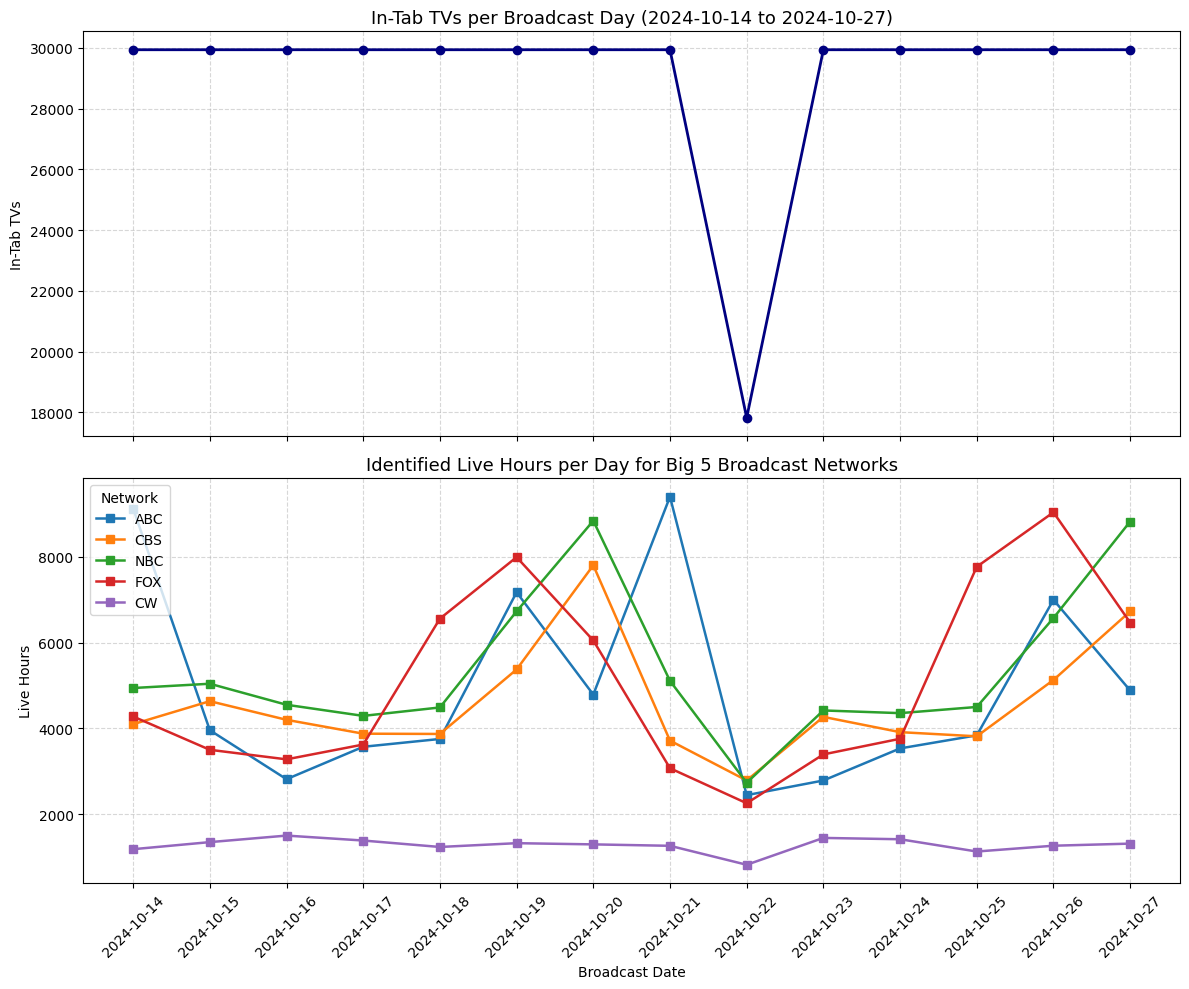

In [45]:
daily_intab_df = acr_clean.groupby('broadcast_date')['tv_id'].nunique().reset_index()
daily_intab_df.columns = ['broadcast_date', 'intab_tvs']

big_five = ['ABC', 'CBS', 'NBC', 'FOX', 'CW']
live_big5 = acr_clean[
    (acr_clean['session_type'] == 'live') &
    (acr_clean['network_code'].isin(big_five))
].copy()

daily_net_hours = live_big5.groupby(['broadcast_date', 'network_code'])['duration_sec'].sum() / 3600.0
daily_net_hours = daily_net_hours.unstack(fill_value=0.0)

fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

axes[0].plot(daily_intab_df['broadcast_date'].astype(str), daily_intab_df['intab_tvs'], marker='o', color='navy', linewidth=2)
axes[0].set_title('In-Tab TVs per Broadcast Day (2024-10-14 to 2024-10-27)', fontsize=13)
axes[0].set_ylabel('In-Tab TVs')
axes[0].grid(True, linestyle='--', alpha=0.5)

for net in big_five:
    if net in daily_net_hours.columns:
        axes[1].plot(daily_net_hours.index.astype(str), daily_net_hours[net], marker='s', label=net, linewidth=1.8)

axes[1].set_title('Identified Live Hours per Day for Big 5 Broadcast Networks', fontsize=13)
axes[1].set_xlabel('Broadcast Date')
axes[1].set_ylabel('Live Hours')
axes[1].legend(title='Network')
axes[1].grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Task 4.2 Spike and broken day

In [46]:
daily_all_live = acr_clean[acr_clean['session_type'] == 'live'].groupby(
    ['broadcast_date', 'network_code']
)['duration_sec'].sum() / 3600.0

spike_date, spike_net = daily_all_live.idxmax()

broken_date = daily_intab_df.loc[daily_intab_df['intab_tvs'].idxmin(), 'broadcast_date']

print(f"Biggest spike (date, network): {spike_date.strftime('%Y-%m-%d')}, {spike_net}")
print(f"Broken day (date): {broken_date.strftime('%Y-%m-%d')}")

Biggest spike (date, network): 2024-10-21, ABC
Broken day (date): 2024-10-22


**Answer:**
1. **What aired during the spike (2024-10-21, ABC):**
   Checking `programs` confirms that ABC aired live NFL *Monday Night Football* (doubleheader featuring Baltimore Ravens at Tampa Bay Buccaneers and Los Angeles Chargers at Arizona Cardinals). Live sports programming generates massive concurrent tuning, driving identified live hours to their two-week peak.
2. **What went wrong with the data on the broken day (2024-10-22):**
   The anomaly on October 22 is an ingestion/collection infrastructure failure rather than an audience shift: in-tab TVs dropped abruptly from 29,940 to 17,816 (40% loss), and viewing hours across all networks plunged simultaneously. A network outage, client-side ACR firmware glitch, or log transmission pipeline failure prevented nearly 12,000 sets from reporting telemetry.
3. **How it distorts ratings and metrics:**
   - **Daily reach and total viewing hours** will be severely understated by ~40% because millions of devices are missing.
   - **Household ratings** ($\text{Rating} = \text{watched} / \text{in-tab}$) will be artificially volatile and biased: if non-reporting TVs were not missing completely at random (e.g., concentrated in specific DMAs, ISP networks, or firmware versions), the denominator and numerator collapse unevenly, distorting ratings.
4. **How to handle it (Drop, Fix, or Flag):**
   **Flag and Drop.**
   - It should be **flagged** in all client and reporting interfaces as an unrecoverable telemetry collection failure.
   - For campaign reporting and currency-grade measurement, it should be **dropped** from multi-day averages and reach/frequency models, as imputing or scaling up a missing 40% across arbitrary geographies introduces severe synthetic bias.

### Task 5.1 Sampling error vs bias

In [47]:
target_programs = ['NFL Football', 'Hannity', 'Unsellable Houses']
t5_ref = ratings_df[ratings_df['telecast'].isin(target_programs)].copy()

date_map = {
    'NFL Football': datetime.date(2024, 10, 27),
    'Hannity': datetime.date(2024, 10, 16),
    'Unsellable Houses': datetime.date(2024, 10, 16)
}
t5_ref['b_date'] = t5_ref['telecast'].map(date_map)

intab_tv_map = daily_intab_df.set_index('broadcast_date')['intab_tvs'].to_dict()

panel_h_daily = daily_weights[daily_weights['resp_type'] == 'H'].copy()
panel_h_daily['b_date'] = pd.to_datetime(panel_h_daily['broadcast_date']).dt.date
intab_panel_map = panel_h_daily.groupby('b_date')['respondent_id'].nunique().to_dict()

t5_rows = []
for _, row in t5_ref.iterrows():
    b_date = row['b_date']
    p = row['reference_hh_rating'] / 100.0

    n_fp = intab_tv_map.get(b_date, np.nan)
    n_p = intab_panel_map.get(b_date, np.nan)

    se_fp = np.sqrt(p * (1.0 - p) / n_fp) * 100.0
    se_p = np.sqrt(p * (1.0 - p) / n_p) * 100.0
    bias = row['tvs_hh_rating'] - row['reference_hh_rating']

    t5_rows.append({
        'telecast': row['telecast'],
        'se_footprint': round(se_fp, 2),
        'se_panel': round(se_p, 2),
        'bias': round(bias, 1)
    })

t5_df = pd.DataFrame(t5_rows)
print(t5_df.to_string(index=False))

         telecast  se_footprint  se_panel  bias
     NFL Football          0.27      0.75 -11.9
          Hannity          0.09      0.24  -1.5
Unsellable Houses          0.11      0.30  -1.6


**Answer:**
1. **Comparison of sampling error:**
   The footprint's standard error ($SE_{\text{footprint}}$) is roughly 2.7 to 2.8 times smaller than the panel's ($SE_{\text{panel}}$), directly scaling with the square root of sample sizes ($\sqrt{29,940 / 3,900} \approx 2.77$). On a large sample of ~30,000 devices, random sampling noise is practically negligible (0.09 to 0.27 rating points).
2. **Sampling error vs. Systematic bias:**
   The systematic bias (the gap between smart-TV ratings and the true reference currency) is vastly larger than the sampling error. For example, for *NFL Football*, the bias is $-11.9$ points—more than 40 times larger than the footprint's sampling error of $0.27$ points!
3. **Does more data shrink bias?**
   **No.** Increasing sample size ($n$) only reduces random sampling error ($\propto 1/\sqrt{n}$). It does not reduce systematic bias, which stems from who is in the sample (opt-in convenience skew toward higher-income, younger households) and what the device cannot see (single TV vs. whole home, lack of person-level co-viewing). A massive, unweighted convenience sample simply measures the wrong number with extreme statistical precision.

### Task 5.2 Answer to the planner

**Answer:**
For the client presentation tomorrow, the raw household rating we observe in this smart-TV feed for Sunday Night Football is 21.2%, but this number must not be presented as a currency-grade estimate. This dataset measures tuning on a single opted-in television device rather than whole-home viewing across all household screens, completely missing viewing on secondary sets and non-participating televisions. Furthermore, the feed tracks only active hardware and misses audiences who watched via digital streaming apps or unlinked setups, while also observing screen tuning rather than verified persons in front of the set. Consequently, due to demographic and technographic sampling skew, the raw feed understates the actual market currency rating of 33.1% by nearly 12 rating points. Before these smart-TV numbers can be deployed for media planning, guarantees, or client evaluation, the device footprint must be personified and calibrated against a representative probability panel using census-balanced weights.

### Bonus

In [48]:
target_bdate = datetime.date(2024, 10, 27)

p_snf = programs[
    (programs['program_name'] == 'NFL Football') &
    (programs['broadcast_date'] == target_bdate) &
    (programs['network_code'] == 'NBC')
].iloc[0]

p_start = pd.to_datetime(p_snf['start_ts'])
p_end = pd.to_datetime(p_snf['end_ts'])

dw_snf = daily_weights.copy()
dw_snf['b_date'] = pd.to_datetime(dw_snf['broadcast_date']).dt.date
dw_snf = dw_snf[dw_snf['b_date'] == target_bdate]

age_attr_id = attributes[attributes['attr_name'] == 'Age in years']['attr_id'].iloc[0]
ages = viewer_attributes[viewer_attributes['attr_id'] == age_attr_id][['respondent_id', 'value']].copy()
ages['age'] = pd.to_numeric(ages['value'], errors='coerce')
a25_54_resp_ids = set(ages[(ages['age'] >= 25) & (ages['age'] <= 54)]['respondent_id'])

v_snf = viewings[
    (viewings['network_code'] == 'NBC') &
    (viewings['playback'] == 'Live')
].copy()

v_snf_start = pd.to_datetime(v_snf['start_ts'])
v_snf_end = pd.to_datetime(v_snf['end_ts'])
v_snf_bdate = (v_snf_start - pd.Timedelta(hours=6)).dt.date

v_snf = v_snf[v_snf_bdate == target_bdate]

o_start = v_snf_start.clip(lower=p_start)
o_end = v_snf_end.clip(upper=p_end)
overlap_sec = (o_end - o_start).dt.total_seconds()
v_snf = v_snf[overlap_sec >= 60.0]

watched_h_ids = v_snf[v_snf['resp_type'] == 'H']['respondent_id'].unique()
weighted_watched_h = dw_snf[
    (dw_snf['resp_type'] == 'H') &
    (dw_snf['respondent_id'].isin(watched_h_ids))
]['weight'].sum()

watched_a25_54_ids = v_snf[
    (v_snf['resp_type'].isin(['R', 'L'])) &
    (v_snf['respondent_id'].isin(a25_54_resp_ids))
]['respondent_id'].unique()
weighted_watched_a25_54 = dw_snf[
    (dw_snf['resp_type'].isin(['R', 'L'])) &
    (dw_snf['respondent_id'].isin(watched_a25_54_ids))
]['weight'].sum()

vpvh = weighted_watched_a25_54 / weighted_watched_h

univ_hh = dw_snf[dw_snf['resp_type'] == 'H']['weight'].sum()
univ_a25_54 = dw_snf[
    (dw_snf['resp_type'].isin(['R', 'L'])) &
    (dw_snf['respondent_id'].isin(a25_54_resp_ids))
]['weight'].sum()

tv_hh_rating = ratings_df[ratings_df['telecast'] == 'NFL Football']['tvs_hh_rating'].iloc[0]
a25_54_rating = tv_hh_rating * vpvh * (univ_hh / univ_a25_54)

print(f"VPVH A25-54: {vpvh:.3f}")
print(f"A25-54 rating (persons): {a25_54_rating:.1f}")

VPVH A25-54: 0.513
A25-54 rating (persons): 11.1


/tmp/ipykernel_1271/1288531899.py:35: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  v_snf = v_snf[overlap_sec >= 60.0]


**Answer:**
This calibration and personification projection relies on three key assumptions about the footprint's homes:
1. **Identical Co-viewing Dynamics:** It assumes that the average number of persons aged 25–54 watching per viewing household (co-viewing behavior) in opted-in smart-TV homes is identical to that observed in the representative Nielsen-style panel.
2. **Equivalent Demographic Composition:** It assumes that the demographic skew of viewers watching on smart TVs mirrors the national population, ignoring the technographic and economic upward bias of smart-TV households demonstrated in Task 2.2.
3. **Device-to-Household Homogeneity:** It assumes that personification ratios derived from whole-household panel measurement (covering all ~2.6 TVs in a home) can be transferred 1-to-1 to a single tuned smart TV set without introducing distortion from unobserved secondary sets.